# Criteo Sponsored Search — EDA, Data Quality & Leakage Audit
**ANLY 530 · KA1 Milestone 1**

A **self-contained** notebook for the 23-field Criteo Sponsored Search Conversion Log. This notebook does not upload, download, or share data. It detects headerless tab-delimited files (and headered TSV/CSV), samples reproducibly, audits missingness and outcome-derived leakage, and examines time coverage. **No model is trained in this notebook.**

Run cells top-to-bottom. Set `DATA_PATH` below to your actual local dataset. Executed results are not included because the complete local dataset was not provided.

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# CHANGE THIS to your real input file. Relative paths are relative to the notebook's working directory.
DATA_PATH = Path("../data/CriteoSearchData")
SAMPLE_ROWS = 500_000    # Sampling cap. If the file has <= this many rows, retain all.
CHUNK_SIZE = 50_000
RANDOM_SEED = 530

CRITEO_COLUMNS = [
    "Sale", "SalesAmountInEuro", "time_delay_for_conversion", "click_timestamp",
    "nb_clicks_1week", "product_price", "product_age_group", "device_type",
    "audience_id", "product_gender", "product_brand", "product_category1",
    "product_category2", "product_category3", "product_category4",
    "product_category5", "product_category6", "product_category7",
    "product_country", "product_id", "product_title", "partner_id", "user_id",
]
OUTCOME_DERIVED = ["SalesAmountInEuro", "time_delay_for_conversion"]

print("Dataset path:", DATA_PATH.resolve())
print("Exists:", DATA_PATH.is_file())
assert DATA_PATH.is_file(), "Set DATA_PATH to the actual local Criteo dataset file."


Dataset path: /Users/kranthikiranreddy/Downloads/criteo-conversion-research/data/CriteoSearchData
Exists: True


## 1 · Robust schema detection and reproducible sampling
The native Criteo file commonly has **no header** and uses **tabs**. Headered CSV/TSV exports also work. We stream through the source and retain up to `SAMPLE_ROWS` uniformly sampled rows using independent random keys, avoiding a prefix-only sample. This requires reading the full source and is not a substitute for recording the original extraction process. The source file itself stays local.

In [2]:
def detect_file_format(path):
    """Return (separator, header_present). Refuse ambiguous or non-Criteo formats."""
    with open(path, "r", encoding="utf-8-sig", errors="replace") as handle:
        first = handle.readline().rstrip("\r\n")
    if not first:
        raise ValueError("Dataset file is empty.")
    # Count separators so a product-title field containing spaces stays a single column.
    delimiter = "\t" if first.count("\t") >= first.count(",") else ","
    fields = next(csv.reader([first], delimiter=delimiter))
    if len(fields) != 23:
        raise ValueError(f"Expected 23 fields, found {len(fields)}; check DATA_PATH and delimiter.")
    header_present = fields[0].strip().lower() == "sale"
    if header_present:
        if [v.strip() for v in fields] != CRITEO_COLUMNS:
            raise ValueError("Detected header, but names/order do not match the expected Criteo schema.")
    else:
        if fields[0].strip() not in {"0", "1"}:
            raise ValueError("First column is not Sale=0/1. Check that this is Criteo click data.")
        try:
            int(fields[3])
        except ValueError as exc:
            raise ValueError("Fourth column is not a Unix click timestamp.") from exc
    return delimiter, header_present


def load_criteo_sample(path, sample_rows=500_000, chunk_size=50_000, seed=530):
    """Read headerless/headered Criteo; uniform bounded random sample of all source rows."""
    if sample_rows < 1 or chunk_size < 1:
        raise ValueError("sample_rows and chunk_size must be positive")
    delimiter, has_header = detect_file_format(path)
    reader_kwargs = dict(sep=delimiter, header=0 if has_header else None,
                         chunksize=chunk_size, low_memory=False)
    if not has_header:
        reader_kwargs["names"] = CRITEO_COLUMNS
    rng = np.random.default_rng(seed)
    sample = pd.DataFrame()
    keys = np.empty(0, dtype=np.float64)
    scanned = 0
    for chunk in pd.read_csv(path, **reader_kwargs):
        chunk.columns = chunk.columns.astype(str).str.strip()
        if chunk.columns.tolist() != CRITEO_COLUMNS:
            raise ValueError(f"Unexpected columns: {chunk.columns.tolist()}")
        scanned += len(chunk)
        new_keys = rng.random(len(chunk))
        candidates = pd.concat((sample, chunk), ignore_index=True)
        candidate_keys = np.concatenate((keys, new_keys))
        if len(candidates) > sample_rows:
            idx = np.argpartition(candidate_keys, sample_rows - 1)[:sample_rows]
            sample = candidates.iloc[idx].reset_index(drop=True)
            keys = candidate_keys[idx]
        else:
            sample = candidates
            keys = candidate_keys
    if scanned == 0:
        raise ValueError("No data rows found")
    sample["Sale"] = pd.to_numeric(sample["Sale"], errors="raise")
    sample["click_timestamp"] = pd.to_numeric(sample["click_timestamp"], errors="raise")
    if not sample["Sale"].isin((0, 1)).all():
        raise ValueError("Sale must be 0 or 1 for every sampled row")
    return sample, scanned, delimiter, has_header

df, scanned_rows, delimiter, had_header = load_criteo_sample(
    DATA_PATH, sample_rows=SAMPLE_ROWS, chunk_size=CHUNK_SIZE, seed=RANDOM_SEED
)
print(f"Separator: {repr(delimiter)} | Header present: {had_header}")
print(f"Scanned: {scanned_rows:,} | Retained: {len(df):,} | Columns: {df.shape[1]}")
print("First six columns:", df.columns[:6].tolist())
assert df.shape[1] == 23 and {"Sale", "click_timestamp"}.issubset(df.columns)
display(df.dtypes.rename("dtype").to_frame())


Separator: '\t' | Header present: False
Scanned: 15,995,634 | Retained: 500,000 | Columns: 23
First six columns: ['Sale', 'SalesAmountInEuro', 'time_delay_for_conversion', 'click_timestamp', 'nb_clicks_1week', 'product_price']


,dtype
Sale,int64
SalesAmountInEuro,float64
time_delay_for_conversion,int64
click_timestamp,int64
nb_clicks_1week,int64
product_price,float64
product_age_group,object
device_type,object
audience_id,object
product_gender,object


## 2 · Target, duplication, and missing-value audit
`-1` often indicates absent information in this dataset, but it is **not interchangeable with pandas NA or zero**. Missing/sentinel reports are shown separately; the negative-one convention must be interpreted column-by-column. The sample is click-level and the presence of repeated entity identifiers does not automatically imply duplicate clicks.

Class counts: {0: 445736, 1: 54264}
Conversion prevalence: 10.8528%
Exact duplicate records: 12


,column,pandas_na_pct,minus_one_sentinel_pct,distinct_values
17,product_category7,0.00,100.00,6
16,product_category6,0.00,98.26,165
15,product_category5,0.00,91.26,668
2,time_delay_for_conversion,0.00,89.18,29093
6,product_age_group,0.00,73.60,11
9,product_gender,0.00,72.96,17
8,audience_id,0.00,71.94,8929
14,product_category4,0.00,65.66,1302
13,product_category3,0.00,46.01,917
10,product_brand,0.00,45.41,16865


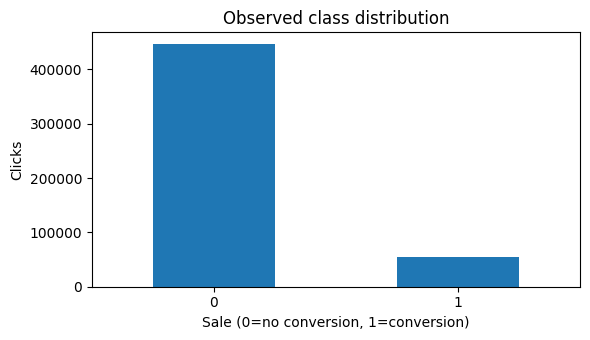

In [3]:
y = df["Sale"].astype("int8")
print("Class counts:", y.value_counts().sort_index().to_dict())
print(f"Conversion prevalence: {y.mean():.4%}")
print("Exact duplicate records:", int(df.duplicated().sum()))

records = []
for col in df.columns:
    values = df[col]
    sentinel = values.astype("string").str.strip().eq("-1").fillna(False)
    records.append({
        "column": col,
        "pandas_na_pct": round(100 * float(values.isna().mean()), 2),
        "minus_one_sentinel_pct": round(100 * float(sentinel.mean()), 2),
        "distinct_values": int(values.nunique(dropna=True)),
    })
quality = pd.DataFrame(records).sort_values("minus_one_sentinel_pct", ascending=False)
display(quality)

fig, ax = plt.subplots(figsize=(6, 3.5))
y.value_counts().sort_index().plot.bar(ax=ax)
ax.set(title="Observed class distribution", xlabel="Sale (0=no conversion, 1=conversion)", ylabel="Clicks")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## 3 · Outcome leakage evidence
`SalesAmountInEuro` and `time_delay_for_conversion` refer to events after the click and must not be used as click-time predictors. The table below shows negative-one sentinel prevalence *conditional on the true Sale label*. Even if the association is imperfect, their information timing makes these variables inadmissible for a prospective model. This is an audit, **not an evaluation of deployed predictive accuracy**.

In [4]:
audit_rows = []
for col in OUTCOME_DERIVED:
    # Numeric parsing handles both '-1' and '-1.0'.
    numeric = pd.to_numeric(df[col], errors="coerce")
    for label in (0, 1):
        subset = numeric[y.eq(label)]
        audit_rows.append({
            "field": col,
            "Sale": label,
            "n": len(subset),
            "minus_one_pct": 100 * float(subset.eq(-1).mean()) if len(subset) else np.nan,
            "non_missing_non_sentinel_pct": 100 * float((subset.notna() & subset.ne(-1)).mean()) if len(subset) else np.nan,
        })
leakage_table = pd.DataFrame(audit_rows)
display(leakage_table)

# The only approved modeling features are columns available at prediction time.
excluded = ["Sale", *OUTCOME_DERIVED, "click_timestamp"]
candidate_predictors = df.drop(columns=excluded)
assert not set(["Sale", *OUTCOME_DERIVED]).intersection(candidate_predictors.columns)
print("Candidate predictors after excluding target/outcomes/time split key:", candidate_predictors.shape[1])
print("Note: further feature-availability checks are required before training.")


,field,Sale,n,minus_one_pct,non_missing_non_sentinel_pct
0,SalesAmountInEuro,0,445736,100.000000,0.000000
1,SalesAmountInEuro,1,54264,0.000000,100.000000
2,time_delay_for_conversion,0,445736,100.000000,0.000000
3,time_delay_for_conversion,1,54264,0.281955,99.718045


Candidate predictors after excluding target/outcomes/time split key: 19
Note: further feature-availability checks are required before training.


## 4 · Timestamp validity, chronological coverage and observed drift
The click timestamp is a **Unix timestamp in seconds**, not a string date. Time-series plots below use the sampled click records and represent *observed recorded outcomes*, not a real-time forecasting backtest. A conversion attribution window means labels close to a historical cutoff may not yet have matured.

Valid timestamp fraction: 100.00%
First recorded click (UTC): 2020-08-03 07:25:18+00:00
Last recorded click (UTC): 2020-11-02 07:24:28+00:00


,clicks,observed_conversion_rate
click_time,,
2020-08-03 00:00:00+00:00,34228,0.124430
2020-08-10 00:00:00+00:00,34890,0.115707
2020-08-17 00:00:00+00:00,32555,0.109200
2020-08-24 00:00:00+00:00,35888,0.109257
2020-08-31 00:00:00+00:00,36684,0.117108
2020-09-07 00:00:00+00:00,35732,0.119697
2020-09-14 00:00:00+00:00,38156,0.112774
2020-09-21 00:00:00+00:00,40131,0.104433
2020-09-28 00:00:00+00:00,40235,0.104188


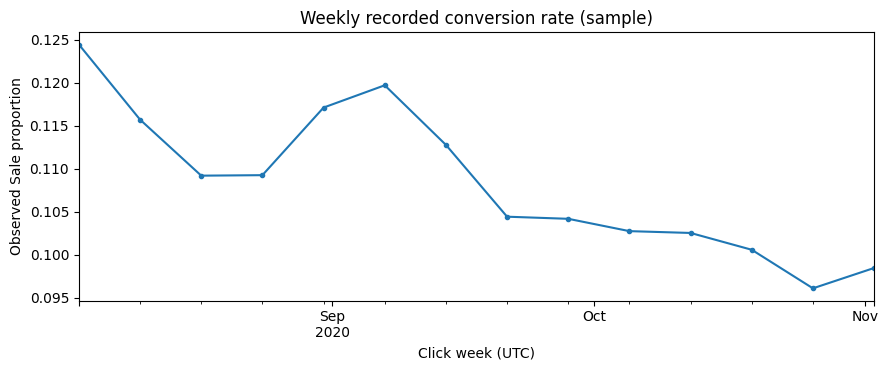

Loaded sample in chronological order: False


In [5]:
timestamps = pd.to_numeric(df["click_timestamp"], errors="coerce")
valid_ts = timestamps.notna() & timestamps.gt(0)
click_dates = pd.to_datetime(timestamps.where(valid_ts), unit="s", utc=True, errors="coerce")
print("Valid timestamp fraction:", f"{click_dates.notna().mean():.2%}")
print("First recorded click (UTC):", click_dates.min())
print("Last recorded click (UTC):", click_dates.max())

weekly = (pd.DataFrame({"click_time": click_dates, "Sale": y})
          .dropna(subset=["click_time"])
          .set_index("click_time")
          .resample("7D")["Sale"]
          .agg(clicks="size", observed_conversion_rate="mean"))
display(weekly)

fig, ax = plt.subplots(figsize=(9, 3.8))
weekly["observed_conversion_rate"].plot(ax=ax, marker="o", markersize=3)
ax.set(title="Weekly recorded conversion rate (sample)", xlabel="Click week (UTC)", ylabel="Observed Sale proportion")
plt.tight_layout()
plt.show()

# Explicit chronology check: our sampling procedure randomizes row order.
print("Loaded sample in chronological order:", bool(timestamps.is_monotonic_increasing))


## 5 · Numeric attributes and complex categorical attributes
`product_title` can contain space-separated hashed tokens in **one tab-separated field**. We inspect token count, not the sensitive/hash values themselves. Treat price and click-count `-1` as a separate missing category for descriptive statistics, rather than silently treating it as a real measurement.

In [6]:
for col in ["product_price", "nb_clicks_1week"]:
    numeric = pd.to_numeric(df[col], errors="coerce")
    cleaned = numeric.mask(numeric.eq(-1))
    print(f"\n{col}")
    print("Numeric valid rows excluding -1:", int(cleaned.notna().sum()))
    display(cleaned.describe(percentiles=[.01, .5, .9, .99]).to_frame("value"))

product_title = df["product_title"].astype("string")
title_tokens = product_title.mask(product_title.eq("-1")).str.split().str.len()
print("Product-title token count (when present):")
display(title_tokens.describe().to_frame("token_count"))



product_price
Numeric valid rows excluding -1: 500000


,value
count,500000.000000
mean,10.831479
std,108.366309
min,0.000000
1%,0.000000
50%,0.000000
90%,1.000000
99%,232.081200
max,22990.000000



nb_clicks_1week
Numeric valid rows excluding -1: 288469


,value
count,288469.000000
mean,391.531329
std,1345.434032
min,0.000000
1%,0.000000
50%,38.000000
90%,787.000000
99%,7573.000000
max,23822.000000


Product-title token count (when present):


,token_count
count,305061
unique,10
top,4
freq,66844


## 6 · Evidence summary and reporting limitations
After running the notebook locally, report the **observed** sample size, conversion prevalence, timestamp coverage, highest missing/sentinel attributes, and the conditional leakage table in your KA1 protocol. Do not report historical high PR-AUC/ROC-AUC as a validated result without rerunning leakage-free models.

**Research design cautions:**
- A uniform random sample of click records followed by time sorting supports a *within-sample chronological* split, not necessarily a full-population temporal deployment simulation.
- Because conversions may be recorded after the click, a historical training boundary needs a **label-maturity gap**. Confirm the source's attribution horizon and define sensitivity analysis accordingly.
- Hash identifiers may repeat across splits and allow memorization; consider an identifier-ablated robustness experiment.
- Missingness/sentinel patterns can correlate with conversion outcomes; investigate availability at prediction time, not just statistical importance.
- Do not publish the original Criteo records to a public GitHub repository.

**Status:** notebook code is ready; findings remain unverified until execution on the actual local file.